In [1]:
import sys
sys.path.append('../')
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder,get_acronym

eps = 1E-7
rcpsize = 12
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
# print(plt.rcParams.keys())
#np.set_printoptions(precision=None)
markers = ['p','o','h','^','s','*']
_linestyles = ['-','--','dotted']
plot_id = 0

depths = {"deepseek":61,
          "llama":32}

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

AB = np.load('n_tokens_20_AB.npy')
BA = np.load('n_tokens_20_BA.npy')

# Compute global vmin and vmax
vmin = min(AB.min(), BA.min())
vmax = max(AB.max(), BA.max())

fig, ax = plt.subplots(1, 2)

# Apply shared color limits
im0 = ax[0].imshow(AB, vmin=vmin, vmax=vmax)
im1 = ax[1].imshow(BA, vmin=vmin, vmax=vmax)

# Add shared colorbar
cbar = fig.colorbar(im0, ax=ax.ravel().tolist(), orientation='horizontal', pad=0.1)

plt.show()

FileNotFoundError: [Errno 2] No such file or directory: './results/santiago/batch_shuffle_0/modelA_llama/modelB_deepseek/n_files_500/min_token_length_40/languageA_english/languageB_spanish/mask_2/k_10/Nbits_1/seed_0/n_tokens_1_avg_0_alignment.npy'

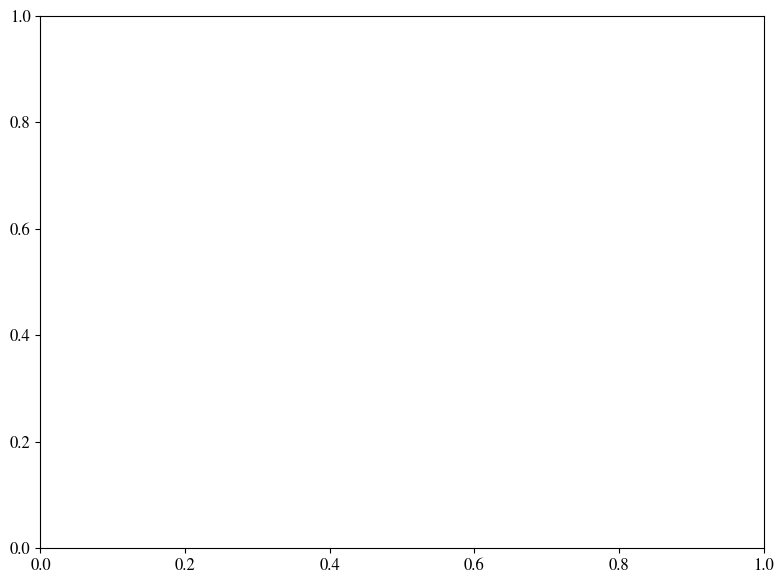

In [4]:
mask = 2
language_pairs = [('english','spanish'),
                  # ('english','italian'),
                  # ('spanish','italian'),
                  # ('german','hungarian'),
                  ]
n_files = 500
figsfolder = makefolder(base=f'./results/figs/translations/',
                        create_folder=True,
                        n_files=n_files,
                        )

batch_size = 10 
Ns = batch_size*n_files

n_tokens_list = [1]
fig,ax = plt.subplots(1,1,
                            figsize=(8,6),
                            # constrained_layout=True,
                            )

k_list = [10]
min_token_length = 40
Nbits_list = [1]

seed_list = [0]
batch_shuffle = 0

modelA = 'llama'
modelB = 'deepseek'
for Nbits_id, Nbits in enumerate(Nbits_list):
  for seed_id, seed in enumerate(seed_list):
    for k_id,k in enumerate(k_list):
      for avg in [0]:
        avg_tokens_II = avg
        avg_tokens_A = avg_tokens_II
        for n_tokens_id,n_tokens in enumerate(n_tokens_list):
            for language_pair_id, language_pair in enumerate(language_pairs):

              (languageA,languageB) = language_pair
              II_folder = makefolder(base=f'./results/santiago/',
                                    batch_shuffle=batch_shuffle,
                                    modelA=modelA,
                                    modelB=modelB,
                                    n_files=n_files,
                                    min_token_length=min_token_length,
                                    languageA=languageA,
                                    languageB=languageB,
                                    mask=mask,
                                    k=k,
                                    Nbits=Nbits,
                                    seed=seed,
                                    )

              alignment = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_A}_alignment.npy')
              II_AB = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_II}_AB.npy')
              II_BA = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_II}_BA.npy')

              IIs = np.array([II_AB,II_BA])
              print(IIs)
              # A_layer_ids = np.arange(1,II_AB.shape[0]+1)

              # ax.plot(A_layer_ids/II_AB.shape[0],
              #         np.diagonal(IIs[0]),
              #         label=f'{_model}[{get_acronym(languageA)}] --> {_model}[{get_acronym(languageB)}]',
              #         linestyle=_linestyles[model_id],
              #         color=colors[0],
              #         )
              # ax.plot(A_layer_ids/II_AB.shape[0],
              #         np.diagonal(IIs[1]),
              #         label=f'{_model}[{get_acronym(languageB)}] --> {_model}[{get_acronym(languageA)}]',
              #         linestyle=_linestyles[model_id],
              #         color=colors[1],
              #         )
              # ax.plot(A_layer_ids/II_AB.shape[0],
              #         np.diagonal(alignment),
              #         label=f'A({_model}[{languageB}] <--> {_model}[{languageA}])',
              #         linestyle=_linestyles[model_id],
              #         color=colors[3],
              #         )


              # np.savetxt(figsfolder+f'{model}_{languageA}_{languageB}_{n_tokens}.txt',
              #           np.array([A_layer_ids,np.diagonal(IIs[0])]).T)
              # print(figsfolder+f'{model}_{languageA}_{languageB}_{n_tokens}')
              # np.savetxt(figsfolder+f'{model}_{languageB}_{languageA}_{n_tokens}.txt',
              #           np.array([A_layer_ids,np.diagonal(IIs[1])]).T)
            # np.savetxt(figsfolder+f'{model}_{languageA}_{languageB}_alignment_{n_tokens}.txt',
            #            np.array([A_layer_ids,np.diagonal(alignment)]).T)


          # box = ax.get_position()
          # ax.set_position([box.x0, box.y0, box.width * 0.8, box.height])
          # ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

          # ax.set_xlabel('Relative Depth')
          # ax.set_ylabel('Information Imbalance')
          # ax.set_ylim(0,1)
          # ax.legend(loc='upper right')
          # ax.set_title(f'{n_tokens=}')
  # fig.savefig(f'{figsfolder}comparison_alignment_{n_tokens}.pdf',
  #               bbox_inches='tight',
                # )
  # fig.savefig(f'{figsfolder}translations_diagonal_{n_tokens}.pdf',
  #               bbox_inches='tight',
  #               )